In [55]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from sklearn import linear_model
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import seaborn as sns

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

# EPSG to be used when setting coordinate reference systems
epsg = 4326 

# Function used for coercing clarity lat/lon to match the 0.2 x 0.2deg grid of TEMPO
# Note: I included the bias term (0.01) to force the lat/lon to match TEMPO lat/lon
def round_002(x):
    out = 0.02*round(x/0.02) + 0.01
    return out

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out

In [2]:
hourly_dat_path  = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-hourly.nc"
diurnal_dat_path  = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-diurnal.nc"

ct_hourly = xr.open_dataset(hourly_dat_path)
ct_diurnal = xr.open_dataset(diurnal_dat_path)




### Basic Linear Model
Here we apply a basic linear model to all data for the study period. This is independent of space / time.

                    time   latitude  longitude  sfc_no2_mean  column_no2_mean
4039 2025-09-04 12:00:00  41.650002 -87.550003     10.151250     4.081628e+15
4087 2025-09-04 12:00:00  41.669998 -87.629997     15.822500     4.954445e+15
4088 2025-09-04 12:00:00  41.669998 -87.610001     10.762500     4.620537e+15
4089 2025-09-04 12:00:00  41.669998 -87.589996     11.576667     4.610096e+15
4091 2025-09-04 12:00:00  41.669998 -87.550003     13.251667     4.801101e+15
0.06472136894959324


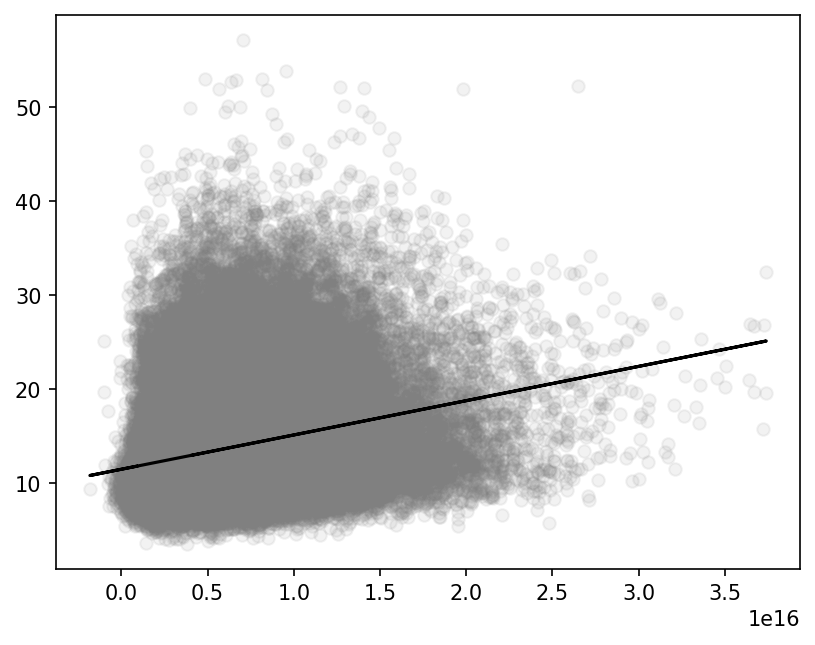

<Axes: xlabel='sfc_no2_mean', ylabel='Density'>

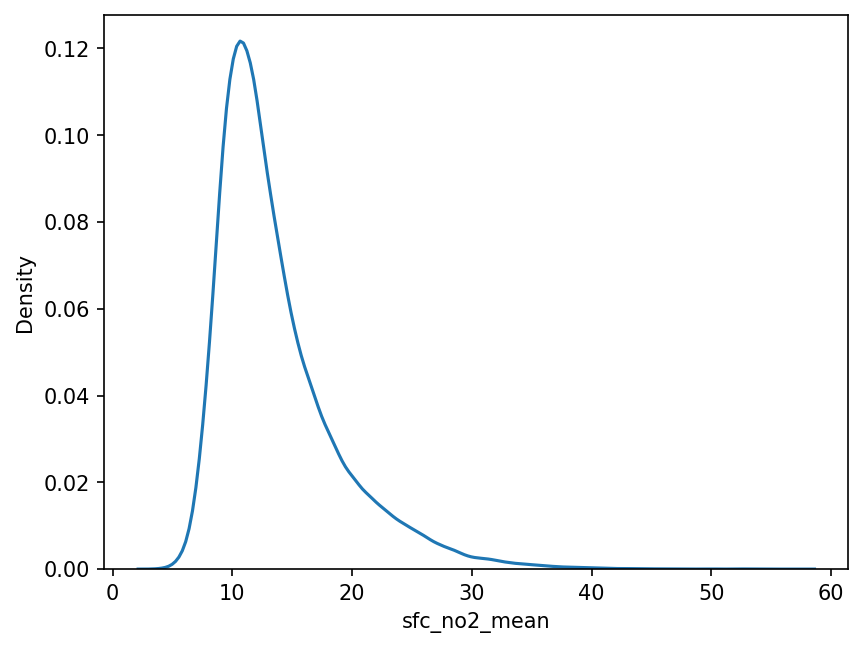

In [5]:
tempo_vals =  ct_hourly.column_no2_mean.to_dataframe().reset_index()
clarity_vals = ct_hourly.sfc_no2_mean.to_dataframe().reset_index()

both = clarity_vals.merge(tempo_vals, on=['latitude','longitude','time']).dropna()
print(both.head())

x = both['column_no2_mean'].to_frame()
y = both['sfc_no2_mean'].to_frame()

model = linear_model.LinearRegression().fit(X=x, y=y)
score = model.score(X=x, y=y)

print(score)

plt.scatter(x, y, color='grey', alpha=0.1)
plt.plot(x, model.predict(x),color='k')

plt.show()

sns.kdeplot(both, x="sfc_no2_mean")

## Linear Regression - Time of Day - Single Weight


       hour   latitude  longitude  sfc_no2_mean  column_no2_mean
10071    11  41.650002 -87.550003     13.849752     5.809331e+15
10119    11  41.669998 -87.629997     18.629538     5.267957e+15
10120    11  41.669998 -87.610001     14.060144     5.336276e+15
10121    11  41.669998 -87.589996     17.227763     5.578089e+15
10122    11  41.669998 -87.570000     17.402100     5.591781e+15
Coef:  [[1.05737016e-15]]
Rank:  1
Intercept:  [8.11181519]
0.13375856073768988


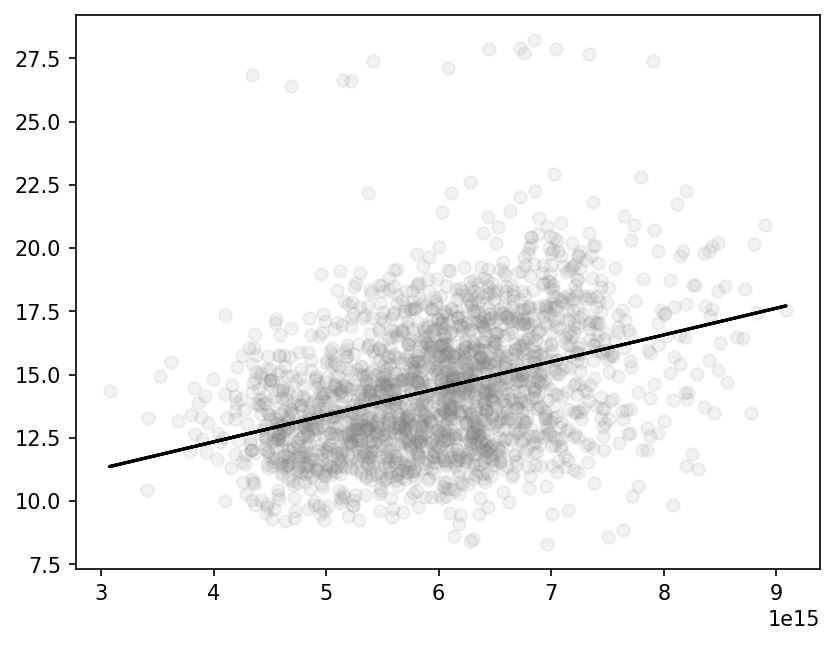

       hour   latitude  longitude  sfc_no2_mean  column_no2_mean  no2_estimate
10071    11  41.650002 -87.550003     13.849752     5.809331e+15     14.254428
10119    11  41.669998 -87.629997     18.629538     5.267957e+15     13.681995
10120    11  41.669998 -87.610001     14.060144     5.336276e+15     13.754234
10121    11  41.669998 -87.589996     17.227763     5.578089e+15     14.009920
10122    11  41.669998 -87.570000     17.402100     5.591781e+15     14.024398


/tmp/ipykernel_12293/3541928214.py:32: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  both['no2_estimate'] = both['column_no2_mean'].apply(lambda x: x*float(coef)+float(intercept))


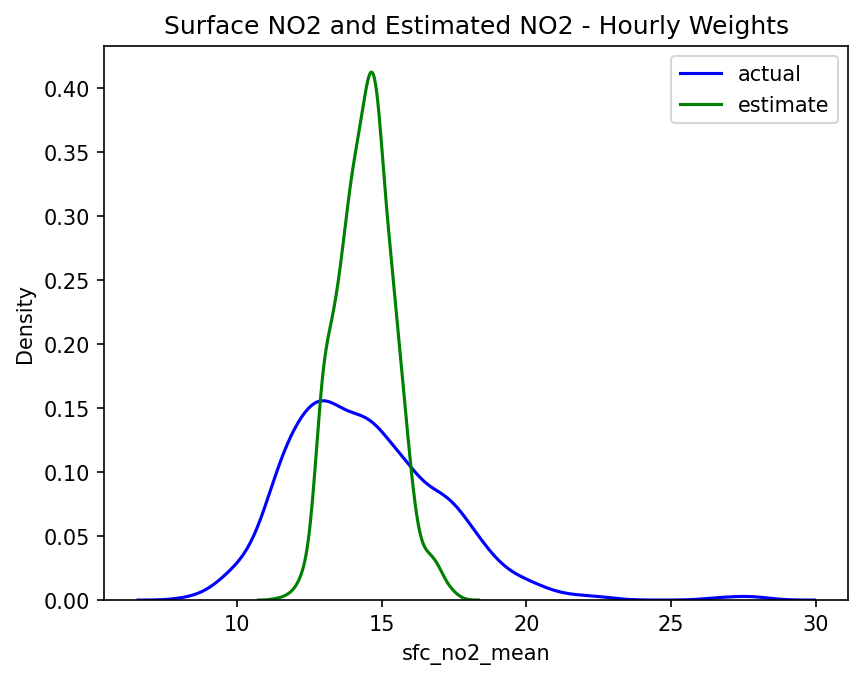

In [ ]:
tempo_vals =  ct_diurnal.column_no2_mean.to_dataframe().reset_index()
clarity_vals = ct_diurnal.sfc_no2_mean.to_dataframe().reset_index()

both = clarity_vals.merge(tempo_vals, on=['latitude','longitude','hour']).dropna()
print(both.head())

x = both['column_no2_mean'].to_frame()
y = both['sfc_no2_mean'].to_frame()

model = linear_model.LinearRegression().fit(X=x, y=y)
score = model.score(X=x, y=y)

coef = model.coef_
rank = model.rank_
intercept = model.intercept_

print("Coef: ", coef)
print("Rank: ", rank)
print("Intercept: ", intercept)

print(score)

plt.scatter(x, y, color='grey', alpha=0.1)
plt.plot(x, model.predict(x),color='k')

plt.show()

# sns.kdeplot(both, x="sfc_no2_mean")

both['no2_estimate'] = both['column_no2_mean'].apply(lambda x: x*float(coef)+float(intercept))
print(both.head())

sns.kdeplot(both, x="sfc_no2_mean", color="blue", label='actual')
sns.kdeplot(both, x='no2_estimate', color="green", label='estimate')
plt.title("Surface NO2 and Estimated NO2 - Hourly Weights")
plt.legend()



## Linear Regression - Time of Day - Hourly Weights

    hour          coef  intercept     score
0     11  8.037608e-16  11.944953  0.141404
1     12  1.328250e-15   9.005151  0.134943
2     13  1.193698e-15   8.750858  0.111381
3     14  1.052220e-15   8.368581  0.081068
4     15  1.073252e-15   6.895271  0.109347
5     16  8.293040e-16   7.917001  0.064404
6     17  7.456288e-16   8.387536  0.055028
7     18  1.166441e-15   6.108015  0.090060
8     19  1.201530e-15   6.212961  0.075708
9     20  1.242921e-15   6.501273  0.114813
10    21  8.371338e-16   8.940245  0.071328
11    22  1.013401e-15   8.458442  0.096267
12    23  9.935751e-16   9.811594  0.115722
   hour   latitude  longitude  sfc_no2_mean  column_no2_mean          coef  \
0    11  41.650002 -87.550003     13.849752     5.809331e+15  8.037608e-16   
1    11  41.669998 -87.629997     18.629538     5.267957e+15  8.037608e-16   
2    11  41.669998 -87.610001     14.060144     5.336276e+15  8.037608e-16   
3    11  41.669998 -87.589996     17.227763     5.578089e+15  8.037608e-

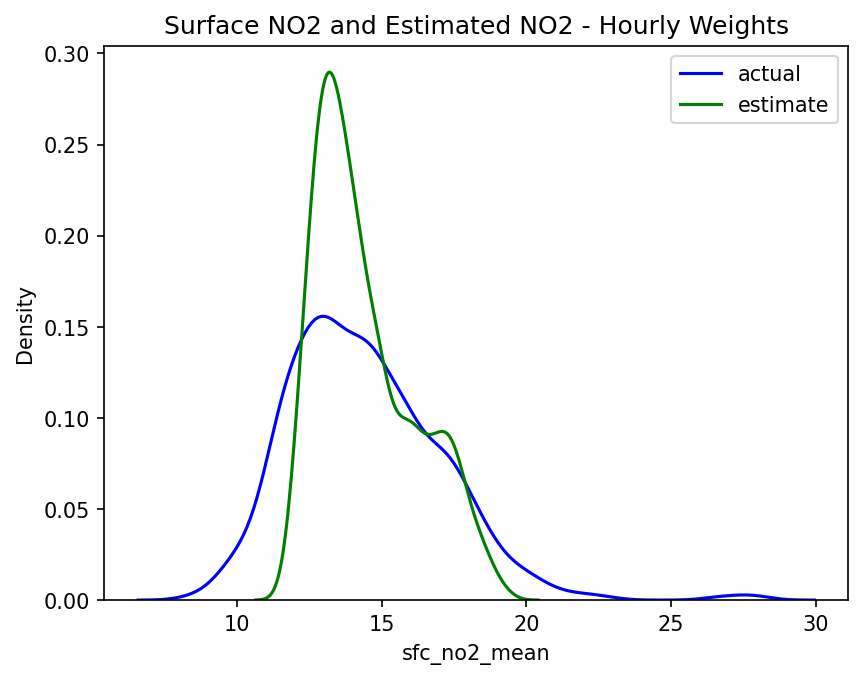

<Axes: xlabel='rmse', ylabel='Density'>

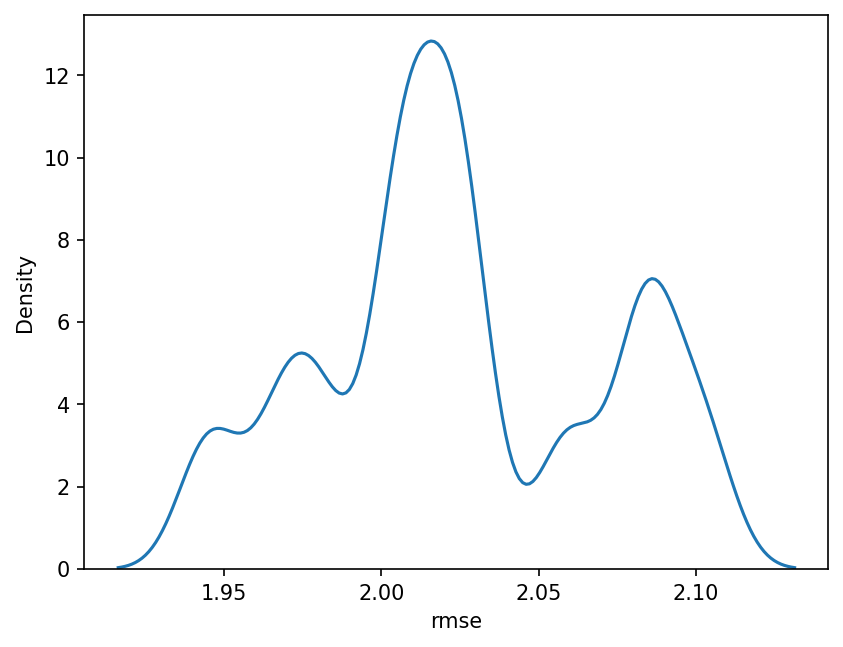

In [ ]:
tempo_vals =  ct_diurnal.column_no2_mean.to_dataframe().reset_index()
clarity_vals = ct_diurnal.sfc_no2_mean.to_dataframe().reset_index()

both = clarity_vals.merge(tempo_vals, on=['latitude', 'longitude', 'hour']).dropna()

x_ = both['column_no2_mean'].to_frame()
y_ = both['sfc_no2_mean'].to_frame()

model_rows = []
for hour in sorted(both['hour'].dropna().unique()):
    x_hour = both.loc[both['hour'] == hour, ['column_no2_mean']]
    y_hour = both.loc[both['hour'] == hour, ['sfc_no2_mean']]

    if len(x_hour) < 2:
        continue

    hour_model = linear_model.LinearRegression().fit(X=x_hour, y=y_hour)
    model_rows.append({
        'hour': hour,
        'coef': float(hour_model.coef_.ravel()[0]),
        'intercept': float(hour_model.intercept_.ravel()[0]),
        'score': hour_model.score(X=x_hour, y=y_hour)
    })

model_vals = pd.DataFrame(model_rows)
print(model_vals)

both = both.merge(model_vals, on='hour', how='left')
both['no2_estimate'] = both['column_no2_mean'] * both['coef'] + both['intercept']

hour_rmse = both.groupby('hour').apply(
    lambda group: rmse(group['sfc_no2_mean'], group['no2_estimate'])
)
both['rmse'] = both['hour'].map(hour_rmse)

print(both.head())

sns.kdeplot(both, x='sfc_no2_mean', color='blue', label='actual')
sns.kdeplot(both, x='no2_estimate', color='green', label='estimate')
plt.title('Surface NO2 and Estimated NO2 - Hourly Weights')
plt.legend()
plt.show()

sns.kdeplot(both, x='rmse')
plt.show()

plt.

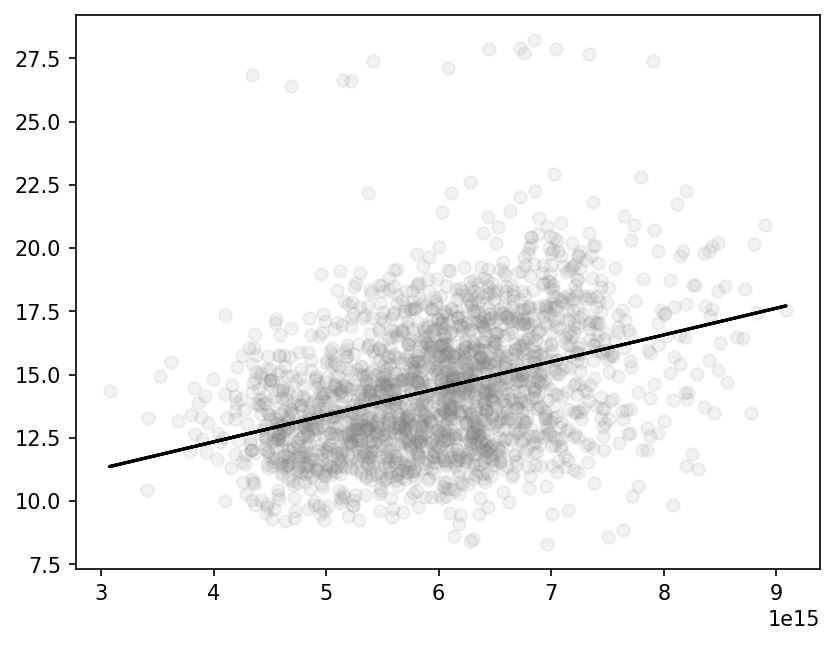

   hour   latitude  longitude  sfc_no2_mean  column_no2_mean          coef  \
0    11  41.650002 -87.550003     13.849752     5.809331e+15  8.037608e-16   
1    11  41.669998 -87.629997     18.629538     5.267957e+15  8.037608e-16   
2    11  41.669998 -87.610001     14.060144     5.336276e+15  8.037608e-16   
3    11  41.669998 -87.589996     17.227763     5.578089e+15  8.037608e-16   
4    11  41.669998 -87.570000     17.402100     5.591781e+15  8.037608e-16   

   intercept     score  no2_estimate  
0  11.944953  0.141404     16.614265  
1  11.944953  0.141404     16.179130  
2  11.944953  0.141404     16.234042  
3  11.944953  0.141404     16.428402  
4  11.944953  0.141404     16.439407  


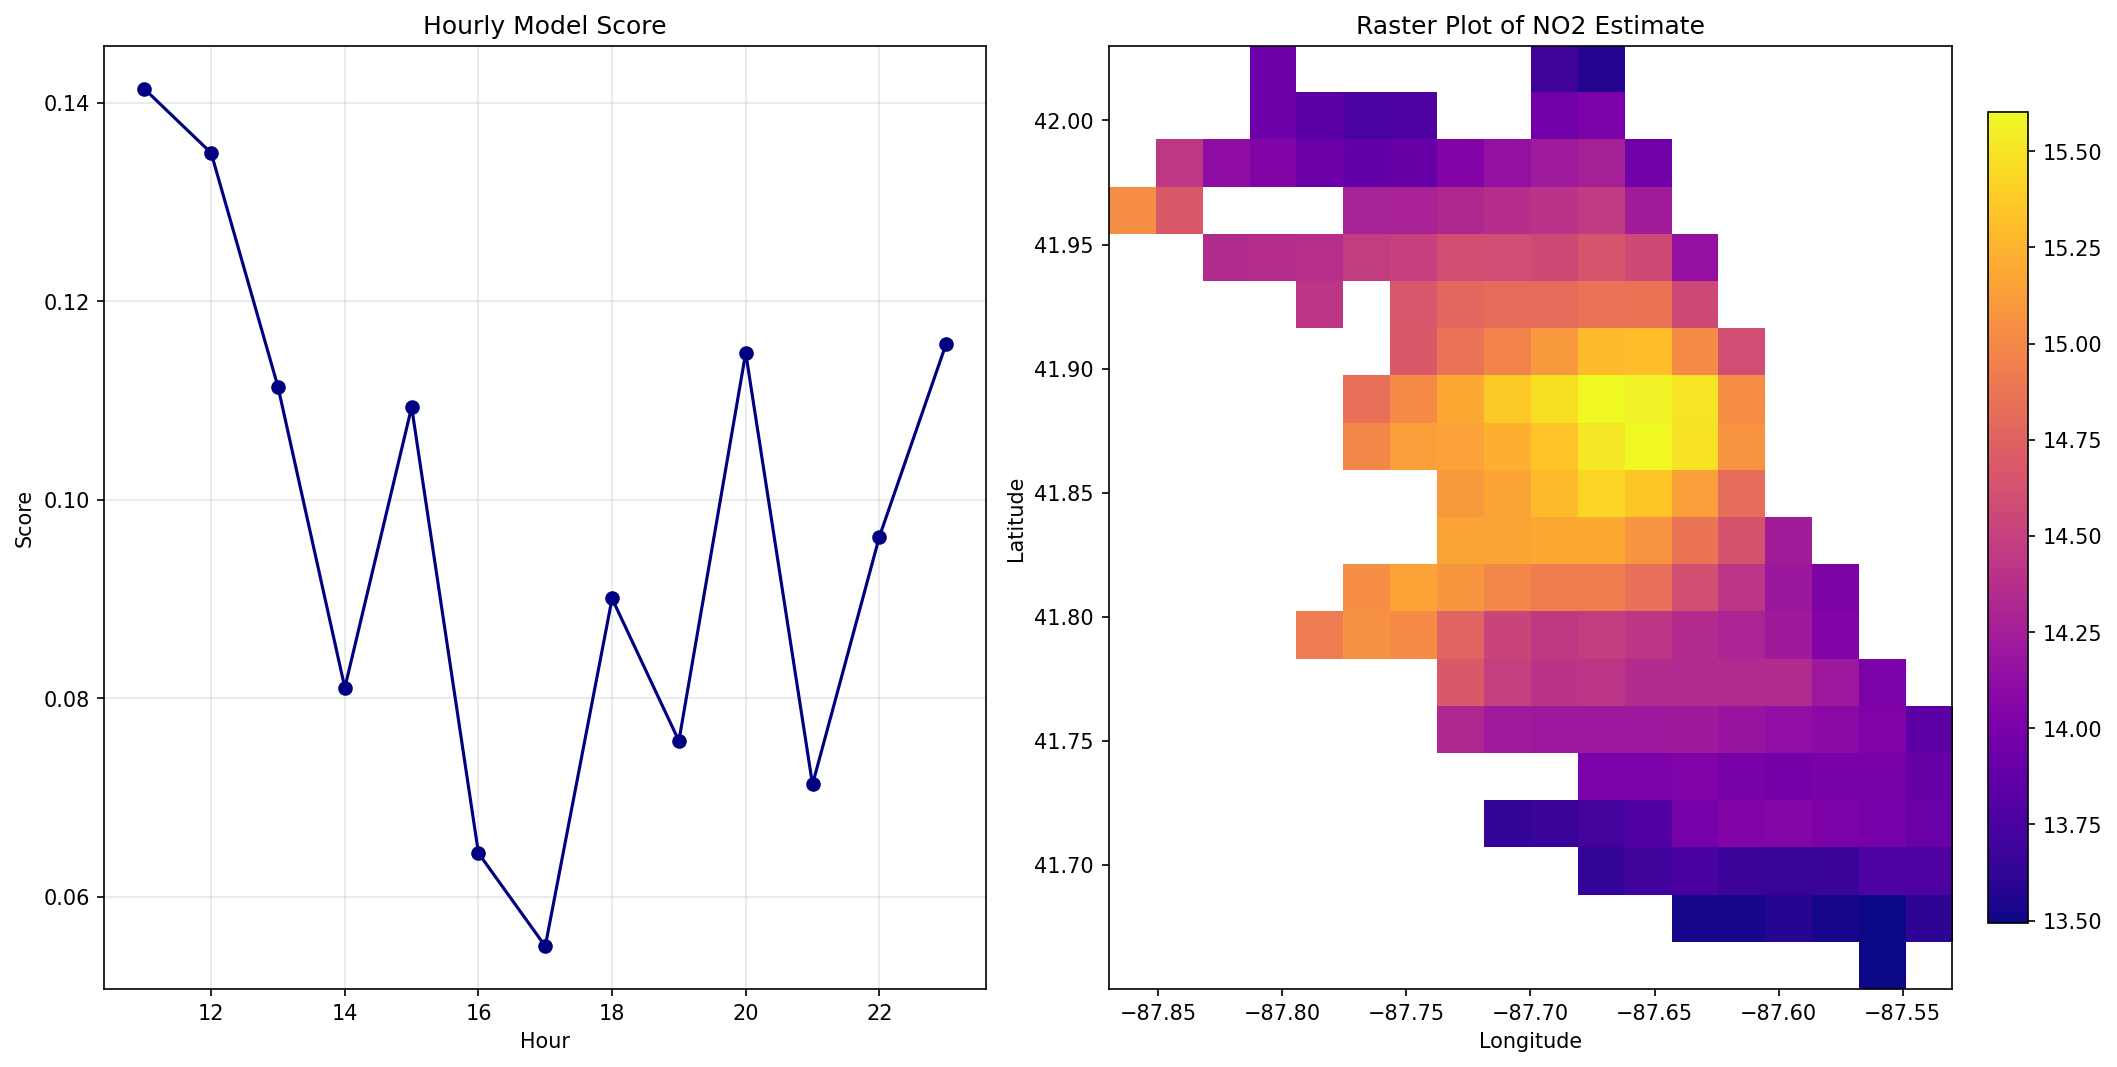

In [50]:
plt.scatter(x, y, color='grey', alpha=0.1)
plt.plot(x, model.predict(x), color='k')

plt.show()

# Attach the hourly model results before computing the estimate and plotting
hour_lookup = model_vals.set_index('hour')
both['coef'] = both['hour'].map(hour_lookup['coef'])
both['intercept'] = both['hour'].map(hour_lookup['intercept'])
both['score'] = both['hour'].map(hour_lookup['score'])
both['no2_estimate'] = both['column_no2_mean'] * both['coef'] + both['intercept']
print(both.head())

# Build gridded rasters from the lat/lon cells in the notebook
score_grid = both.pivot_table(
    index='latitude',
    columns='longitude',
    values='score',
    aggfunc='mean',
).sort_index(axis=0).sort_index(axis=1)
estimate_grid = both.pivot_table(
    index='latitude',
    columns='longitude',
    values='no2_estimate',
    aggfunc='mean',
).sort_index(axis=0).sort_index(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

hourly_scores = model_vals.sort_values('hour')
axes[0].plot(hourly_scores['hour'], hourly_scores['score'], marker='o', color='navy')
axes[0].set_title('Hourly Model Score')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Score')
axes[0].grid(True, alpha=0.3)

estimate_image = axes[1].imshow(
    estimate_grid.to_numpy(),
    extent=[estimate_grid.columns.min(), estimate_grid.columns.max(), estimate_grid.index.min(), estimate_grid.index.max()],
    origin='lower',
    cmap='plasma',
    aspect='equal',
)
axes[1].set_title('Raster Plot of NO2 Estimate')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
fig.colorbar(estimate_image, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()

# Random Plotting


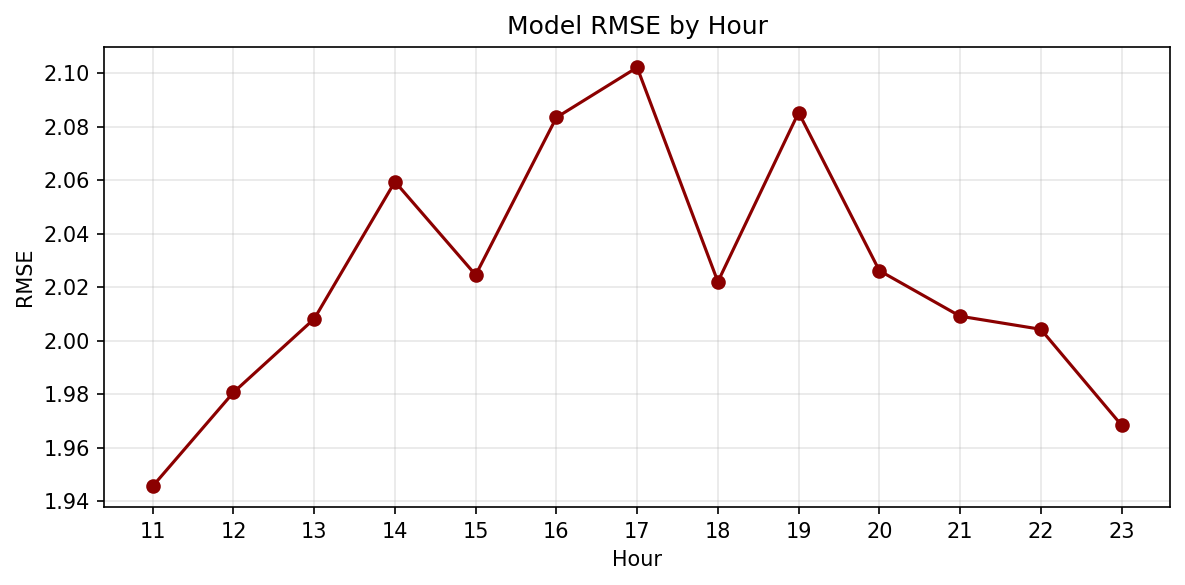

In [ ]:
hour_rmse_df = hour_rmse.reset_index()
hour_rmse_df.columns = ['hour', 'rmse']

plt.figure(figsize=(8, 4))
plt.plot(hour_rmse_df['hour'], hour_rmse_df['rmse'], marker='o', color='darkred')
plt.xticks(hour_rmse_df['hour'])
plt.xlabel('Hour')
plt.ylabel('RMSE')
plt.title('Model RMSE by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()